In [1]:
%load_ext nb_black
import os
from glob import glob
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
import pickle
from scipy import stats
from os.path import join
import scipy
from pathlib import Path
from collections import defaultdict
from datetime import datetime
import seaborn as sns

<IPython.core.display.Javascript object>

In [2]:
plt.rcParams.update(
    {
        "font.size": 6,  # Default font size for all text
        "axes.titlesize": 6,  # Axes title
        "axes.labelsize": 6,  # Axes labels
        "xtick.labelsize": 6,  # X-axis tick labels
        "ytick.labelsize": 6,  # Y-axis tick labels
        "legend.fontsize": 6,  # Legend text
        "figure.titlesize": 6,  # Figure title
        "lines.linewidth": 0.5,  # Default line width
        "figure.figsize": (9 / 2.54, 6 / 2.54),  # Default figure size in cm
        "figure.dpi": 150,  # Default DPI for figures
        "xtick.major.size": 1,  # X-axis major tick length
        "ytick.major.size": 1,  # Y-axis major tick length
        "figure.constrained_layout.use": True,  # Use constrained layout by default
    }
)

<IPython.core.display.Javascript object>

In [3]:
tol_bright_20 = [
    "#4477AA",  # blue
    "#66CCEE",  # cyan
    "#228833",  # green
    "#CCBB44",  # mustard
    "#EE6677",  # red
    "#AA3377",  # purple
    "#BBBBBB",  # grey
    "#77AADD",  # light blue
    "#EE8866",  # orange
    "#EEDD88",  # pale yellow
    "#FFAABB",  # pink
    "#99DDFF",  # sky blue
    "#44AA99",  # teal
    "#117733",  # dark green
    "#332288",  # indigo
    "#DDCC77",  # sand
    "#CC6677",  # rose
    "#88CCAA",  # mint
    "#999933",  # olive
    "#882255",  # burgundy
]

colors20 = sns.color_palette(tol_bright_20)
colors20

[(0.26666666666666666, 0.4666666666666667, 0.6666666666666666),
 (0.4, 0.8, 0.9333333333333333),
 (0.13333333333333333, 0.5333333333333333, 0.2),
 (0.8, 0.7333333333333333, 0.26666666666666666),
 (0.9333333333333333, 0.4, 0.4666666666666667),
 (0.6666666666666666, 0.2, 0.4666666666666667),
 (0.7333333333333333, 0.7333333333333333, 0.7333333333333333),
 (0.4666666666666667, 0.6666666666666666, 0.8666666666666667),
 (0.9333333333333333, 0.5333333333333333, 0.4),
 (0.9333333333333333, 0.8666666666666667, 0.5333333333333333),
 (1.0, 0.6666666666666666, 0.7333333333333333),
 (0.6, 0.8666666666666667, 1.0),
 (0.26666666666666666, 0.6666666666666666, 0.6),
 (0.06666666666666667, 0.4666666666666667, 0.2),
 (0.2, 0.13333333333333333, 0.5333333333333333),
 (0.8666666666666667, 0.8, 0.4666666666666667),
 (0.8, 0.4, 0.4666666666666667),
 (0.5333333333333333, 0.8, 0.6666666666666666),
 (0.6, 0.6, 0.2),
 (0.5333333333333333, 0.13333333333333333, 0.3333333333333333)]

<IPython.core.display.Javascript object>

In [4]:
def get_meta_from_file_path(file_path):
    meta = file_path.split("/")
    version = meta[-2]
    name = meta[-1].split("_")
    var = name[0]
    mdl = name[2]
    exp = name[3]
    label = name[4]
    time = name[-1].split(".")[0].split("-")
    time0 = time[0]
    time1 = time[1]

    return var, mdl, exp, label, version, time0, time1

<IPython.core.display.Javascript object>

In [5]:
cmip6_data_dir = Path.cwd().parent
res_dir = Path.cwd().parent / "processed"

<IPython.core.display.Javascript object>

In [6]:
# land_area_dict prepared from previous step
with open(res_dir / "land_area_related" / "land_area_dict.pkl", "rb") as f:
    land_area_dict = pickle.load(f)

# land_area_dict prepared from previous step
with open(res_dir / "land_area_related" / "areacella_dict.pkl", "rb") as f:
    areacella_dict = pickle.load(f)

# land_area_dict prepared from previous step
with open(res_dir / "land_area_related" / "sftlf_dict.pkl", "rb") as f:
    sftlf_dict = pickle.load(f)

<IPython.core.display.Javascript object>

In [7]:
file_paths = sorted([i for i in res_dir.rglob("*.nc") if "annual_data" in str(i)])
print(len(file_paths))

143


<IPython.core.display.Javascript object>

In [8]:
def get_global_annual_dataset(ds, land_area):

    global_vars = {}
    for var in ds.data_vars:
        da = ds[var]
        units = da.attrs["units"]

        if units == "K":
            da_global = (da * land_area).sum(
                dim=["lat", "lon"], min_count=1
            ) / land_area.sum(dim=["lat", "lon"])
        elif units == "kg m-2 yr-1" or units == "kg m-2":
            da_global = (da * land_area).sum(dim=["lat", "lon"], min_count=1)

            if "fN" in var or "fBNF" in var:
                da_global = da_global / 1e9
                units = units.replace("kg m-2", "MtN")
            else:
                da_global = da_global / 1e12
                if var in [
                    "nLand",
                    "nVeg",
                    "nLitter",
                    "nSoil",
                    "nMineral",
                ]:
                    units = units.replace("kg m-2", "GtN")
                else:
                    units = units.replace("kg m-2", "GtC")

        else:
            raise ValueError(f"Unsupported units: {units}")

        da_global.attrs = da.attrs.copy()
        da_global.attrs["units"] = units

        global_vars[var] = da_global

    ds_global = xr.Dataset(global_vars)
    ds_global.attrs = ds.attrs

    return ds_global

<IPython.core.display.Javascript object>

In [9]:
%%time
ds_global_list = []
for f in file_paths:
    mdl_exp_label = f.name.split("_annual")[0]
    print("start:", mdl_exp_label)
    mdl, exp, label = mdl_exp_label.split("_")

    land_area = land_area_dict[mdl]
    ds = xr.open_dataset(f)
    
    lat_identical = ds.lat.equals(land_area.lat)
    lon_identical = ds.lon.equals(land_area.lon)

    if not lat_identical or not lon_identical:
        print(
            mdl,
            "Lat/Lon not identical. Reindex land_area to ds coordinates using nearest neighbour \n",
        )
        land_area = land_area.reindex(lat=ds.lat, lon=ds.lon, method="nearest")
        assert ds.lat.equals(land_area.lat) and ds.lon.equals(
            land_area.lon
        ), "Reindex failed, unmatch lat/lon not from numeric issue."

    ds_global = get_global_annual_dataset(ds, land_area)
    ds_global = ds_global.expand_dims(
        model=[mdl],
        experiment=[exp],
    )
    ds_global_list.append(ds_global)

start: ACCESS-ESM1-5_1pctCO2-bgc_r1i1p1f1
start: ACCESS-ESM1-5_1pctCO2-rad_r1i1p1f1
start: ACCESS-ESM1-5_1pctCO2_r1i1p1f1
start: ACCESS-ESM1-5_historical_r1i1p1f1
start: ACCESS-ESM1-5_ssp126_r1i1p1f1
start: ACCESS-ESM1-5_ssp245_r1i1p1f1
start: ACCESS-ESM1-5_ssp370_r1i1p1f1
start: ACCESS-ESM1-5_ssp585_r1i1p1f1
start: BCC-CSM2-MR_1pctCO2-bgc_r1i1p1f1
start: BCC-CSM2-MR_1pctCO2_r1i1p1f1
start: BCC-CSM2-MR_historical_r1i1p1f1
start: BCC-CSM2-MR_ssp126_r1i1p1f1
start: BCC-CSM2-MR_ssp245_r1i1p1f1
start: BCC-CSM2-MR_ssp370_r1i1p1f1
start: BCC-CSM2-MR_ssp585_r1i1p1f1
start: CESM2-WACCM_1pctCO2_r1i1p1f1
start: CESM2-WACCM_historical_r1i1p1f1
start: CESM2-WACCM_ssp126_r1i1p1f1
start: CESM2-WACCM_ssp245_r1i1p1f1
start: CESM2-WACCM_ssp370_r1i1p1f1
start: CESM2-WACCM_ssp585_r1i1p1f1
start: CESM2_1pctCO2-bgc_r1i1p1f1
start: CESM2_1pctCO2-rad_r1i1p1f1
start: CESM2_1pctCO2_r1i1p1f1
start: CESM2_historical_r1i1p1f1
start: CMCC-CM2-SR5_1pctCO2_r1i1p1f1
start: CMCC-CM2-SR5_historical_r1i1p1f1
start: CMCC

ValueError: too many values to unpack (expected 3)

<IPython.core.display.Javascript object>

In [10]:
ds_global_annual = xr.combine_by_coords(ds_global_list, combine_attrs="override")
ds_global_annual = ds_global_annual[sorted(ds_global_annual.data_vars)]

<IPython.core.display.Javascript object>

In [11]:
mdl_list = ds_global_annual.model.data
exp_list = ds_global_annual.experiment.data

<IPython.core.display.Javascript object>

In [12]:
exp_list_histssp = [i for i in exp_list if "hist" in i or "ssp" in i]
exp_list_1pctco2 = [i for i in exp_list if "1pct" in i]

<IPython.core.display.Javascript object>

In [13]:
def _plot_vars_by_exp(ds, exp_list, var_list, delta=False, mean_std=False):
    col = len(exp_list)
    row = len(var_list)

    fig, axs = plt.subplots(
        row,
        col,
        figsize=(3.5 * col / 2.54, 3.5 * row / 2.54),
    )

    for i, var in enumerate(var_list):
        y_min = np.inf
        y_max = -np.inf

        for j, exp in enumerate(exp_list):
            ax = axs[i, j]
            da = ds[var].sel(experiment=exp)
            units = da.attrs["units"]

            if delta:
                baseline_year = 2015 if "ssp" in exp else 1850
                da = da - da.sel(time=baseline_year)

            for mdl, color in zip(mdl_list, colors20):
                values = da.sel(model=mdl)
                if ds["nVeg"].sel(model=mdl).sum() == 0:
                    linestyle = "--"
                else:
                    linestyle = "-"

                ax.plot(
                    da.time,
                    values,
                    label=mdl,
                    linewidth=0.5,
                    color=color,
                    linestyle=linestyle,
                )

                y_min = min(y_min, values.min().data)
                y_max = max(y_max, values.max().data)
                y_range = y_max - y_min

            if mean_std:
                mean = da.mean(dim="model")
                std = da.std(dim="model")

                ax.plot(
                    da.time,
                    mean,
                    color="black",
                    linewidth=1.5,
                    label="multi-model mean",
                )
                ax.fill_between(
                    da.time,
                    mean - std,
                    mean + std,
                    color="black",
                    alpha=0.15,
                    label="±1 SD",
                    linewidth=0,
                )

            if i == 0:
                ax.set_title(exp)

        for ax in axs[i, :]:
            ax.set_ylim(y_min - y_range * 0.05, y_max + y_range * 0.05)
        for ax in axs[i, 1:]:
            ax.tick_params(axis="y", labelleft=False)

        prefix = "Δ" if delta else ""
        axs[i, 0].set_ylabel(prefix + var + f" ({units})")

    # Single figure-level legend at the bottom
    handles, labels = axs[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.05),
        ncol=5,
        frameon=False,
    )

<IPython.core.display.Javascript object>

In [14]:
state_vars = [
    "cVeg",
    "cLitter",
    "cSoil",
    "cProduct",
    "cLand",
    "nVeg",
    "nLitter",
    "nSoil",
    "nMineral",
    "nLand",
]

<IPython.core.display.Javascript object>

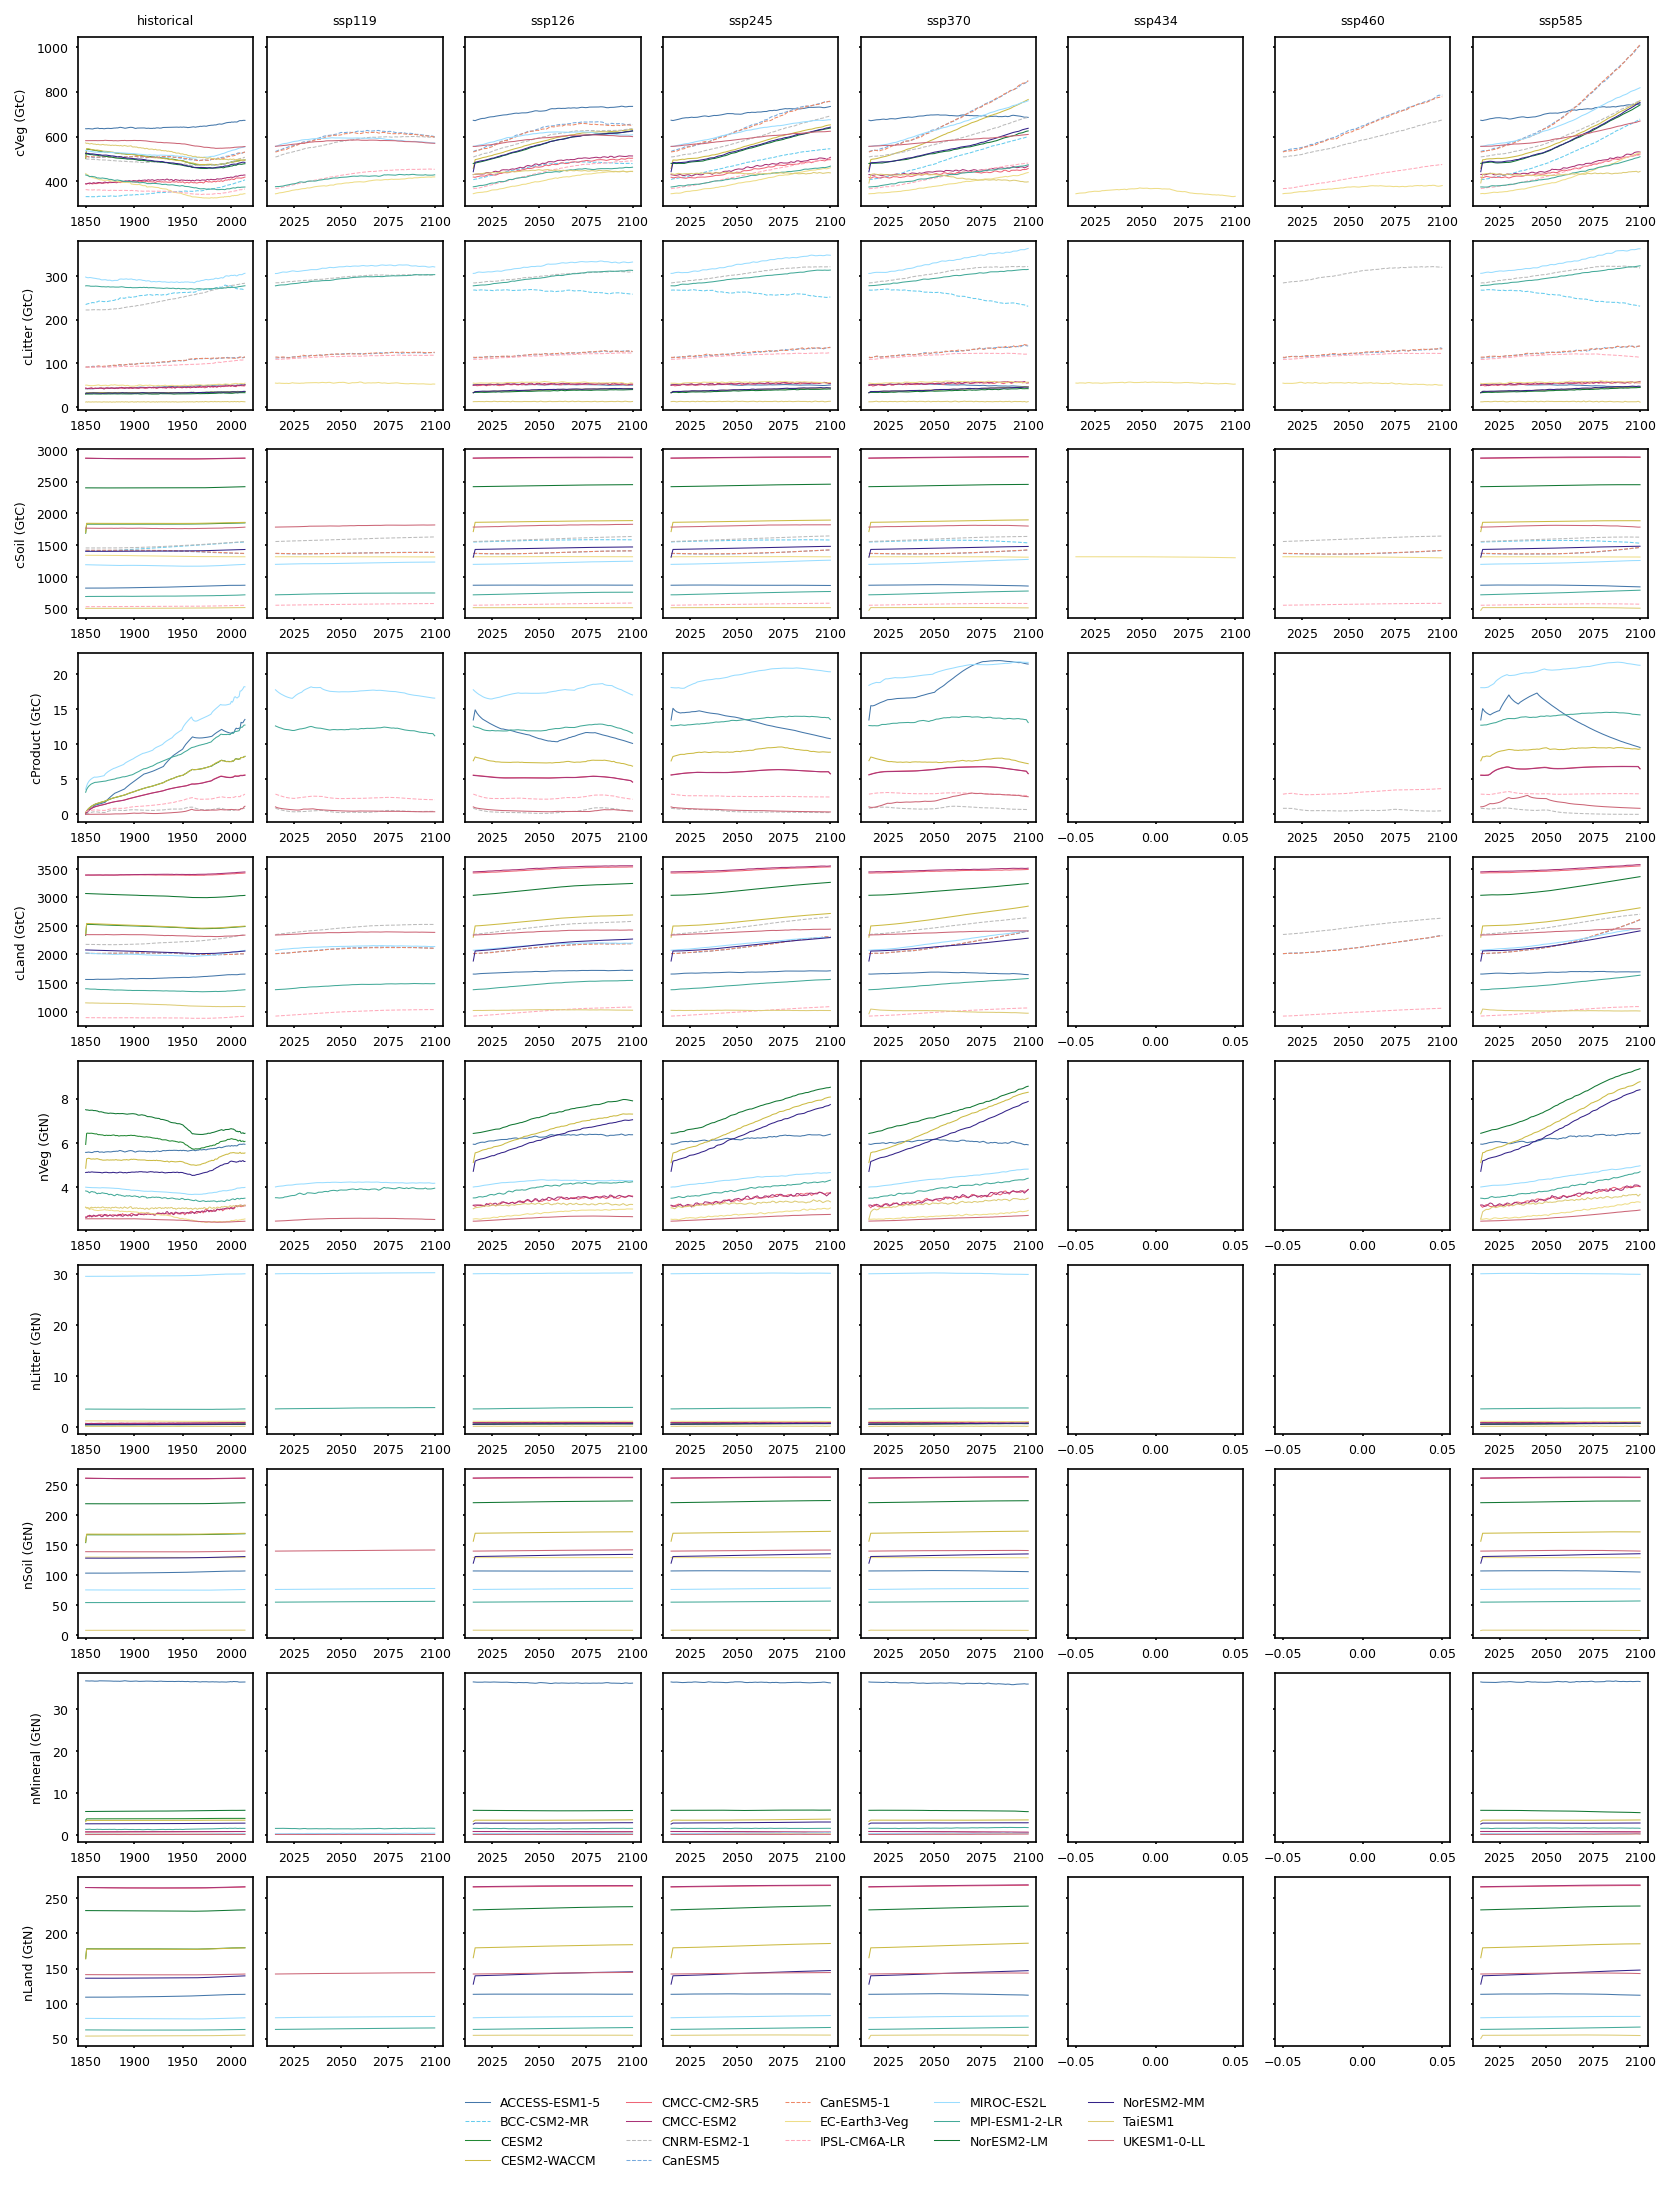

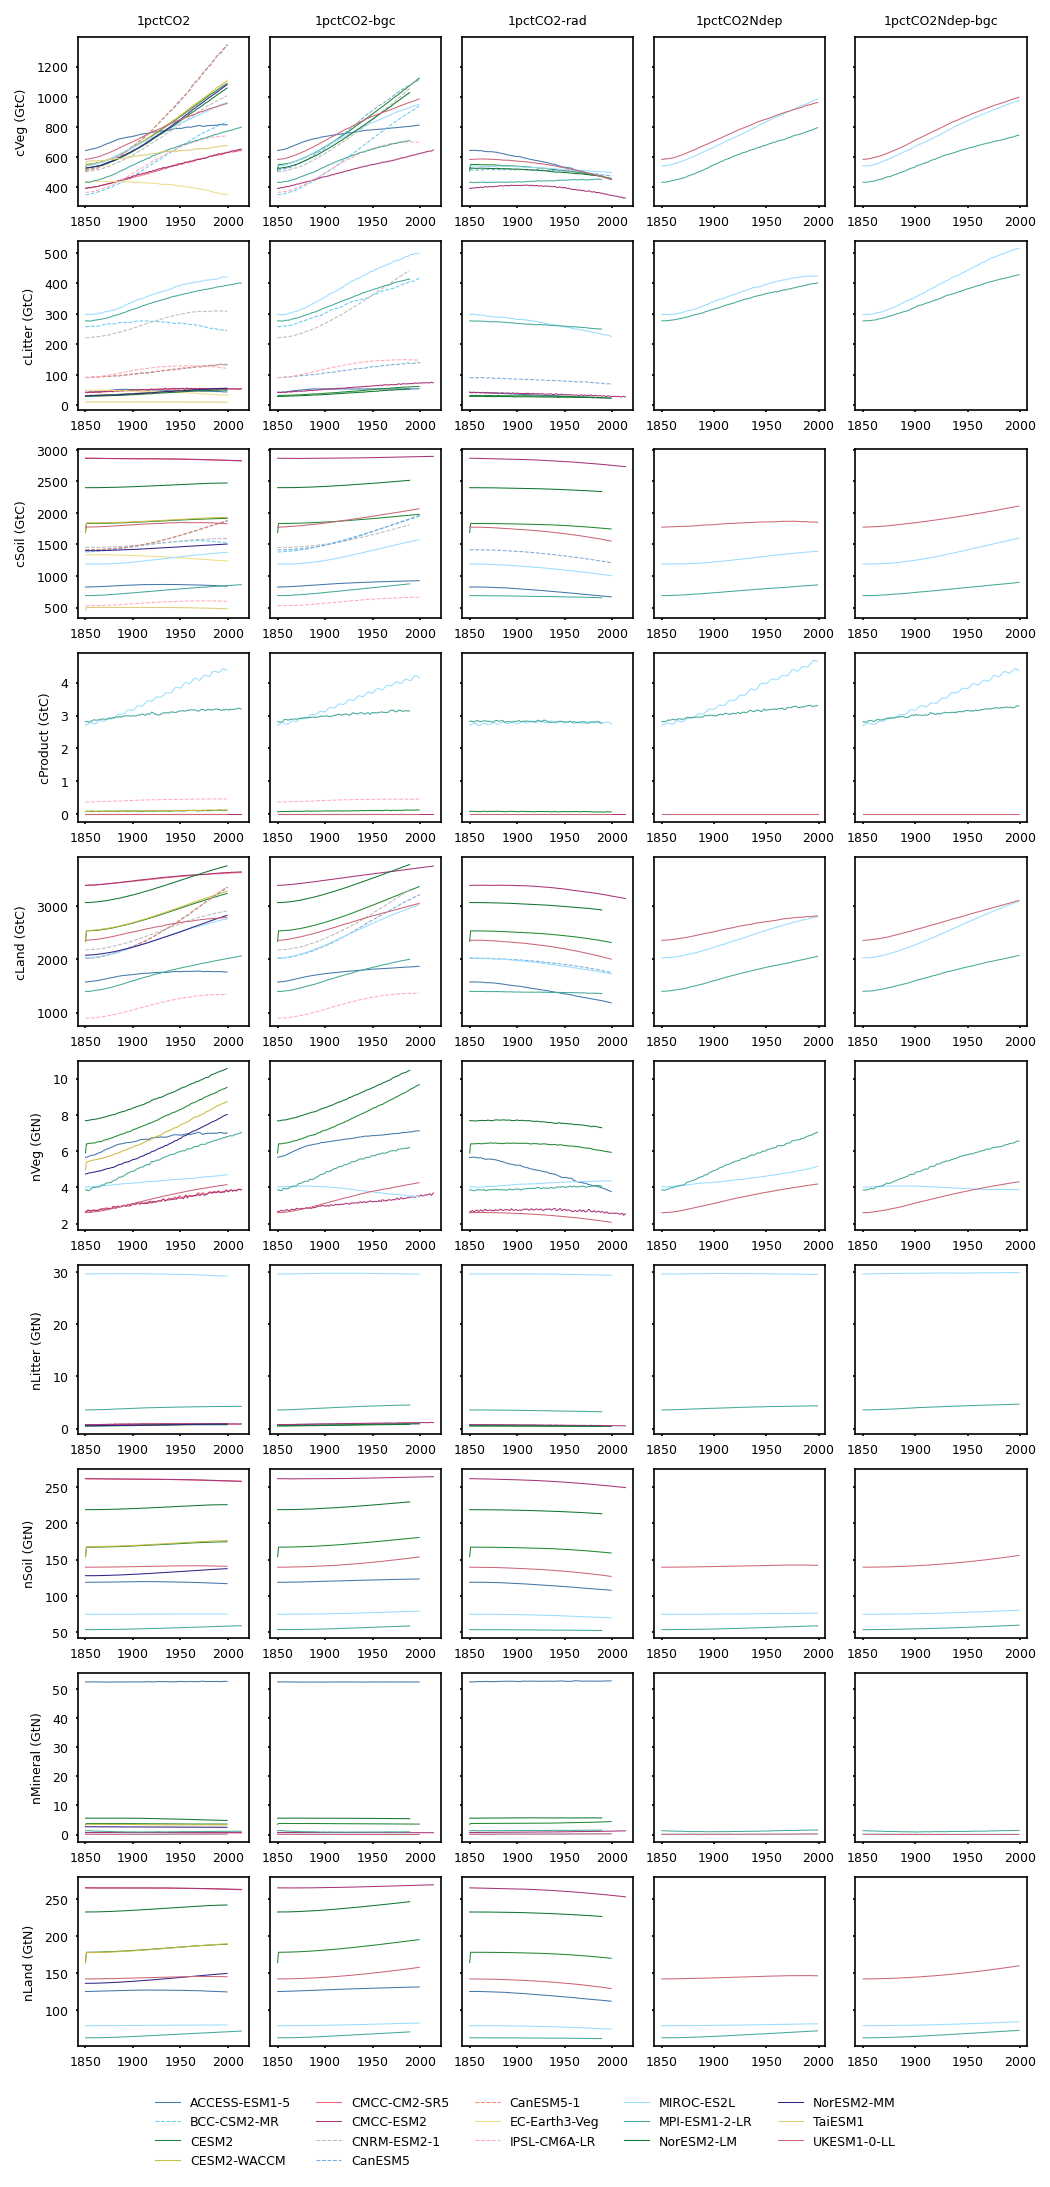

<IPython.core.display.Javascript object>

In [15]:
_plot_vars_by_exp(ds_global_annual, exp_list_histssp, state_vars)
_plot_vars_by_exp(ds_global_annual, exp_list_1pctco2, state_vars)

In [16]:
to_correct = []
for var in state_vars:
    for mdl in mdl_list:
        for exp in exp_list:
            da = ds_global_annual[var].sel(model=mdl, experiment=exp).dropna("time")

            if da.size < 3:
                continue

            diff = abs(np.diff(da.data))
            typical_diff = np.median(diff)

            if var in ["cVeg", "cLitter", "cSoil", "cProduct", "cLand"]:
                jump = diff > 20
            if var in ["nVeg", "nLitter", "nSoil", "nMineral", "nLand"]:
                jump = diff > 0.2

            if jump.any():
                jump_indices = np.where(jump)[0]

                print(f"\n{var} | {mdl} | {exp}")

                for idx in jump_indices:
                    start = max(0, idx - 2)
                    end = min(len(da), idx + 4)

                    print(f"  Jump: {da.time.data[idx]}-{da.time.data[idx + 1]}")
                    for i in range(start, end):
                        if i == 0:
                            print(f"    {da.time.data[i]}: " f"value={da.data[i]:.5g}")
                        else:
                            print(
                                f"    {da.time.data[i]}: "
                                f"value={da.data[i]:.5g}, "
                                f"diff={da.data[i] - da.data[i - 1]:+.5g}"
                            )
                to_correct.append([var, mdl, exp, da.time[idx].item()])


cVeg | CESM2 | 1pctCO2
  Jump: 1850-1851
    1850: value=506
    1851: value=549.11, diff=+43.108
    1852: value=549.1, diff=-0.0095215
    1853: value=549.96, diff=+0.85693

cVeg | CESM2 | 1pctCO2-bgc
  Jump: 1850-1851
    1850: value=506.08
    1851: value=549.05, diff=+42.971
    1852: value=548.96, diff=-0.0849
    1853: value=548.88, diff=-0.081421

cVeg | CESM2 | 1pctCO2-rad
  Jump: 1850-1851
    1850: value=505.85
    1851: value=548.71, diff=+42.864
    1852: value=549.03, diff=+0.31793
    1853: value=548.58, diff=-0.44421

cVeg | CESM2 | historical
  Jump: 1850-1851
    1850: value=502.39
    1851: value=543.88, diff=+41.498
    1852: value=543.66, diff=-0.22321
    1853: value=542.92, diff=-0.74255

cVeg | CESM2-WACCM | 1pctCO2
  Jump: 1850-1851
    1850: value=502.5
    1851: value=544.99, diff=+42.489
    1852: value=544.97, diff=-0.016663
    1853: value=546.6, diff=+1.6252

cVeg | CESM2-WACCM | historical
  Jump: 1850-1851
    1850: value=503.42
    1851: value=546.09,

<IPython.core.display.Javascript object>

In [17]:
to_correct

[['cVeg', 'CESM2', '1pctCO2', 1850],
 ['cVeg', 'CESM2', '1pctCO2-bgc', 1850],
 ['cVeg', 'CESM2', '1pctCO2-rad', 1850],
 ['cVeg', 'CESM2', 'historical', 1850],
 ['cVeg', 'CESM2-WACCM', '1pctCO2', 1850],
 ['cVeg', 'CESM2-WACCM', 'historical', 1850],
 ['cVeg', 'CESM2-WACCM', 'ssp126', 2015],
 ['cVeg', 'CESM2-WACCM', 'ssp245', 2015],
 ['cVeg', 'CESM2-WACCM', 'ssp370', 2015],
 ['cVeg', 'CESM2-WACCM', 'ssp585', 2015],
 ['cVeg', 'NorESM2-MM', 'ssp126', 2015],
 ['cVeg', 'NorESM2-MM', 'ssp245', 2015],
 ['cVeg', 'NorESM2-MM', 'ssp370', 2015],
 ['cVeg', 'NorESM2-MM', 'ssp585', 2015],
 ['cVeg', 'TaiESM1', '1pctCO2', 1850],
 ['cVeg', 'TaiESM1', 'ssp370', 2015],
 ['cVeg', 'TaiESM1', 'ssp585', 2015],
 ['cSoil', 'CESM2', '1pctCO2', 1850],
 ['cSoil', 'CESM2', '1pctCO2-bgc', 1850],
 ['cSoil', 'CESM2', '1pctCO2-rad', 1850],
 ['cSoil', 'CESM2', 'historical', 1850],
 ['cSoil', 'CESM2-WACCM', '1pctCO2', 1850],
 ['cSoil', 'CESM2-WACCM', 'historical', 1850],
 ['cSoil', 'CESM2-WACCM', 'ssp126', 2015],
 ['cSoil

<IPython.core.display.Javascript object>

In [18]:
ds_global_annual_corrected = ds_global_annual.copy(deep=True)

<IPython.core.display.Javascript object>

In [19]:
# Correct the identified initial-year jumps by linear extrapolation
# from the following two years
for var, mdl, exp, year in to_correct:
    da = ds_global_annual_corrected[var].sel(model=mdl, experiment=exp)
    idx = np.where(da.time.data == year)[0][0]

    if idx + 2 >= da.size:
        continue

    da.data[idx] = da.data[idx + 1] + (da.data[idx + 1] - da.data[idx + 2])

<IPython.core.display.Javascript object>

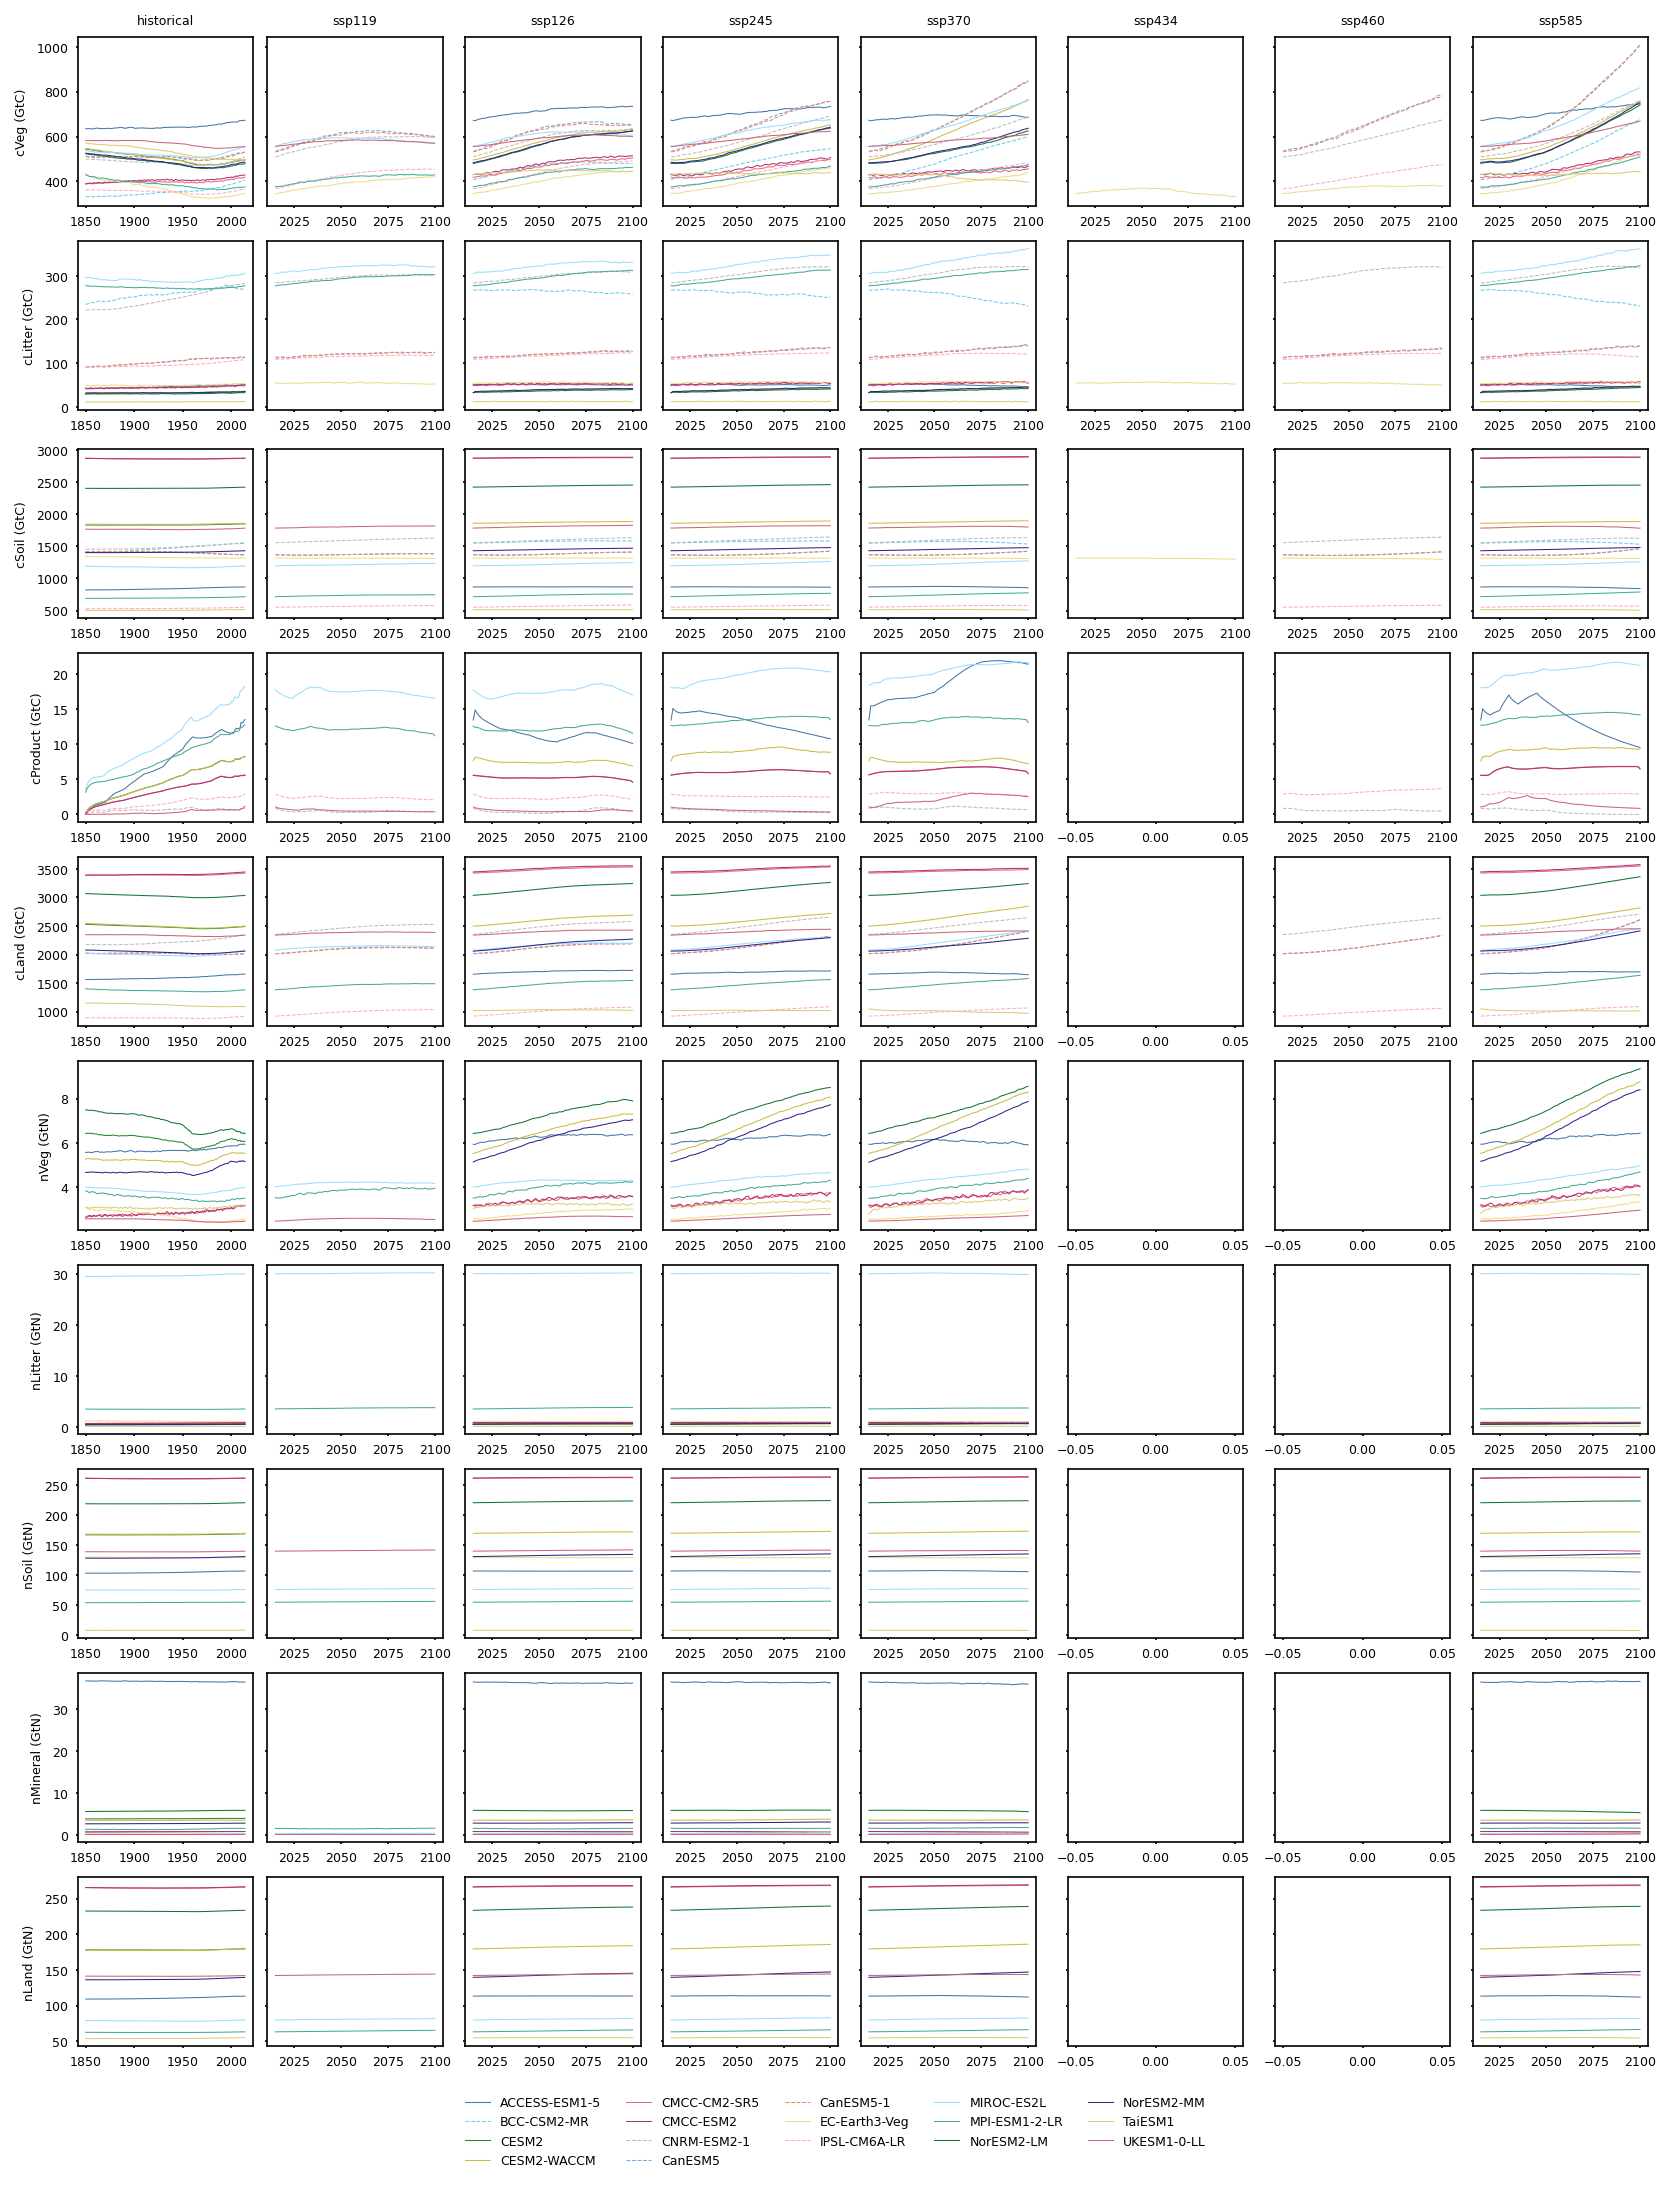

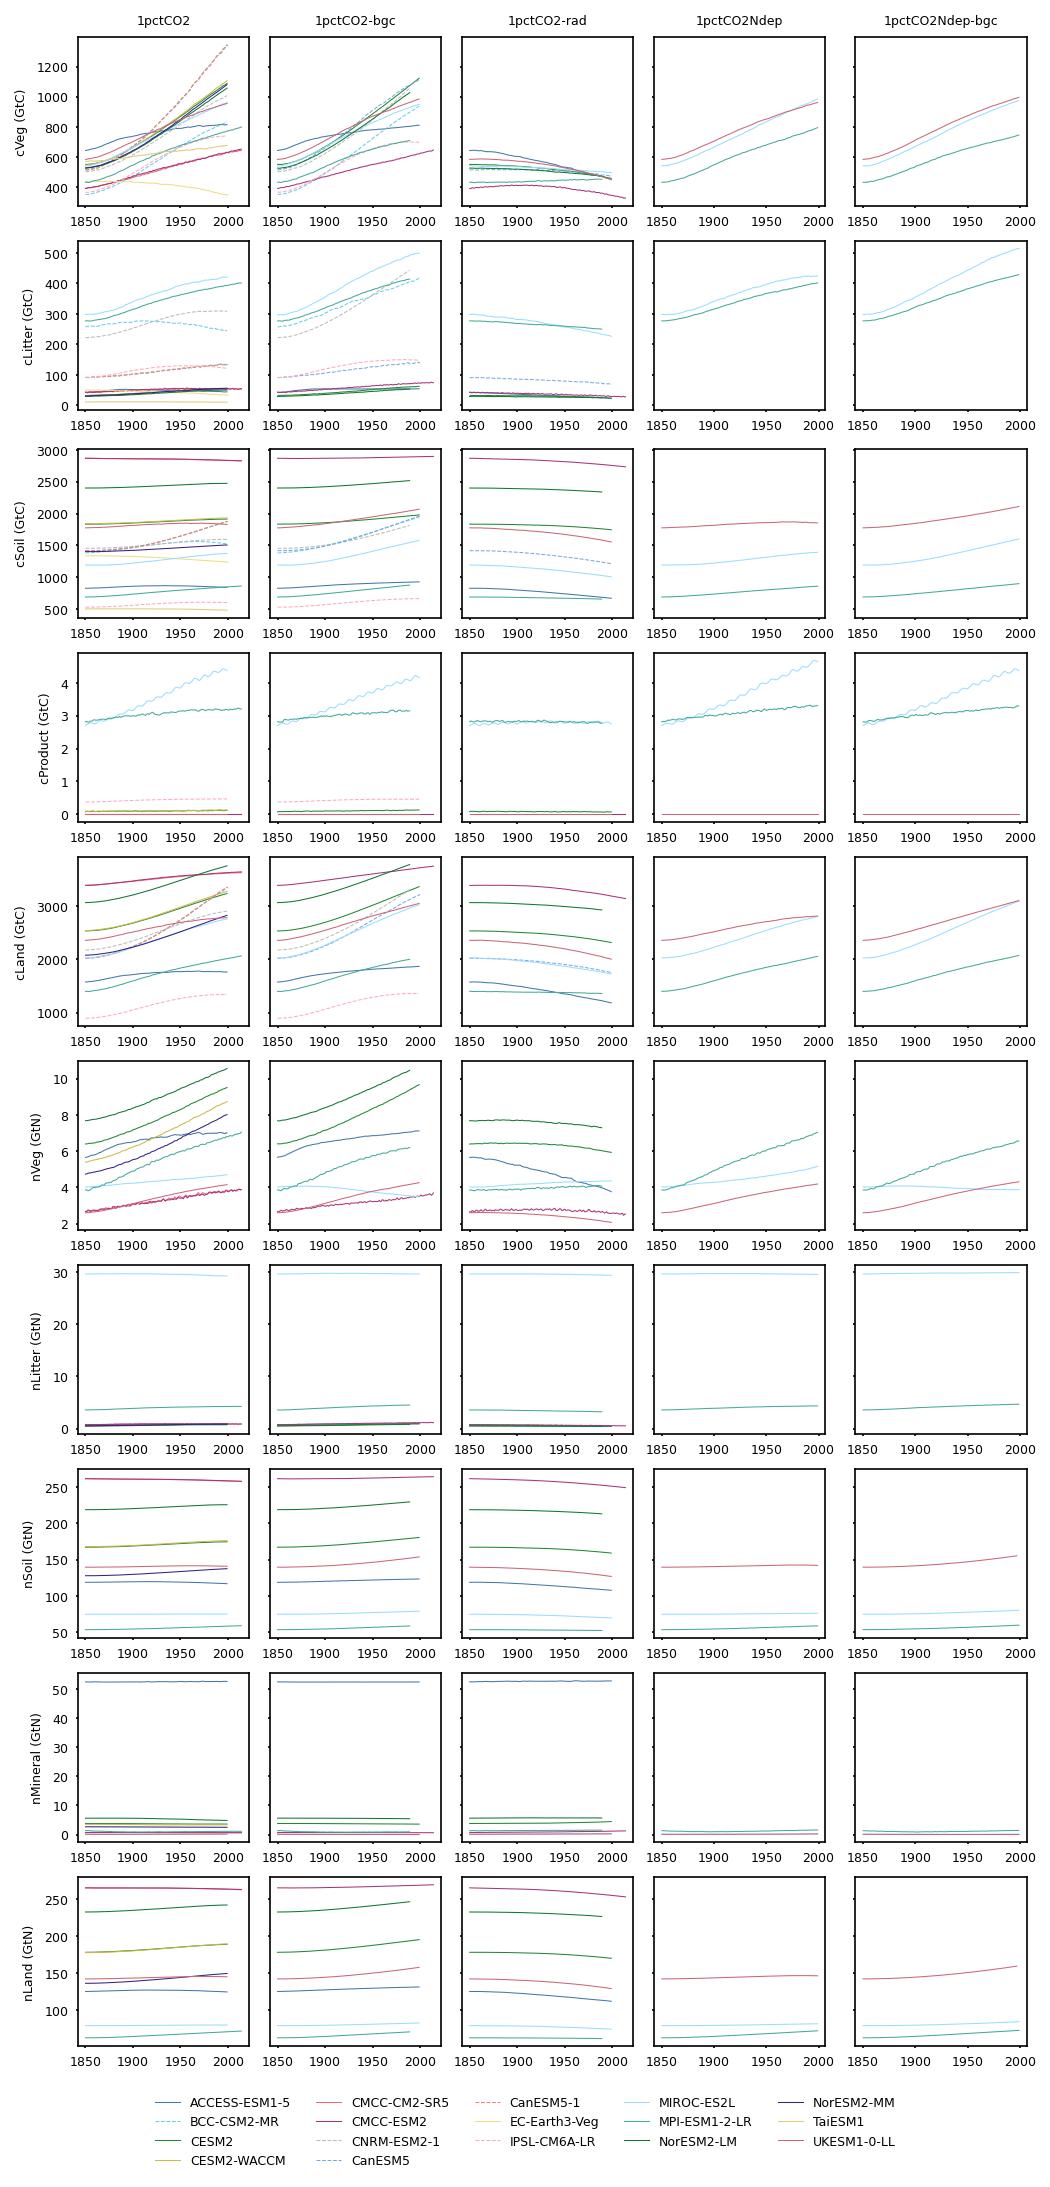

<IPython.core.display.Javascript object>

In [20]:
_plot_vars_by_exp(ds_global_annual_corrected, exp_list_histssp, state_vars)
_plot_vars_by_exp(ds_global_annual_corrected, exp_list_1pctco2, state_vars)

In [21]:
flux_vars = ["npp", "gpp", "ra", "rh", "nbp", "fBNF", "fNnetmin", "fNup", "fNloss"]

<IPython.core.display.Javascript object>

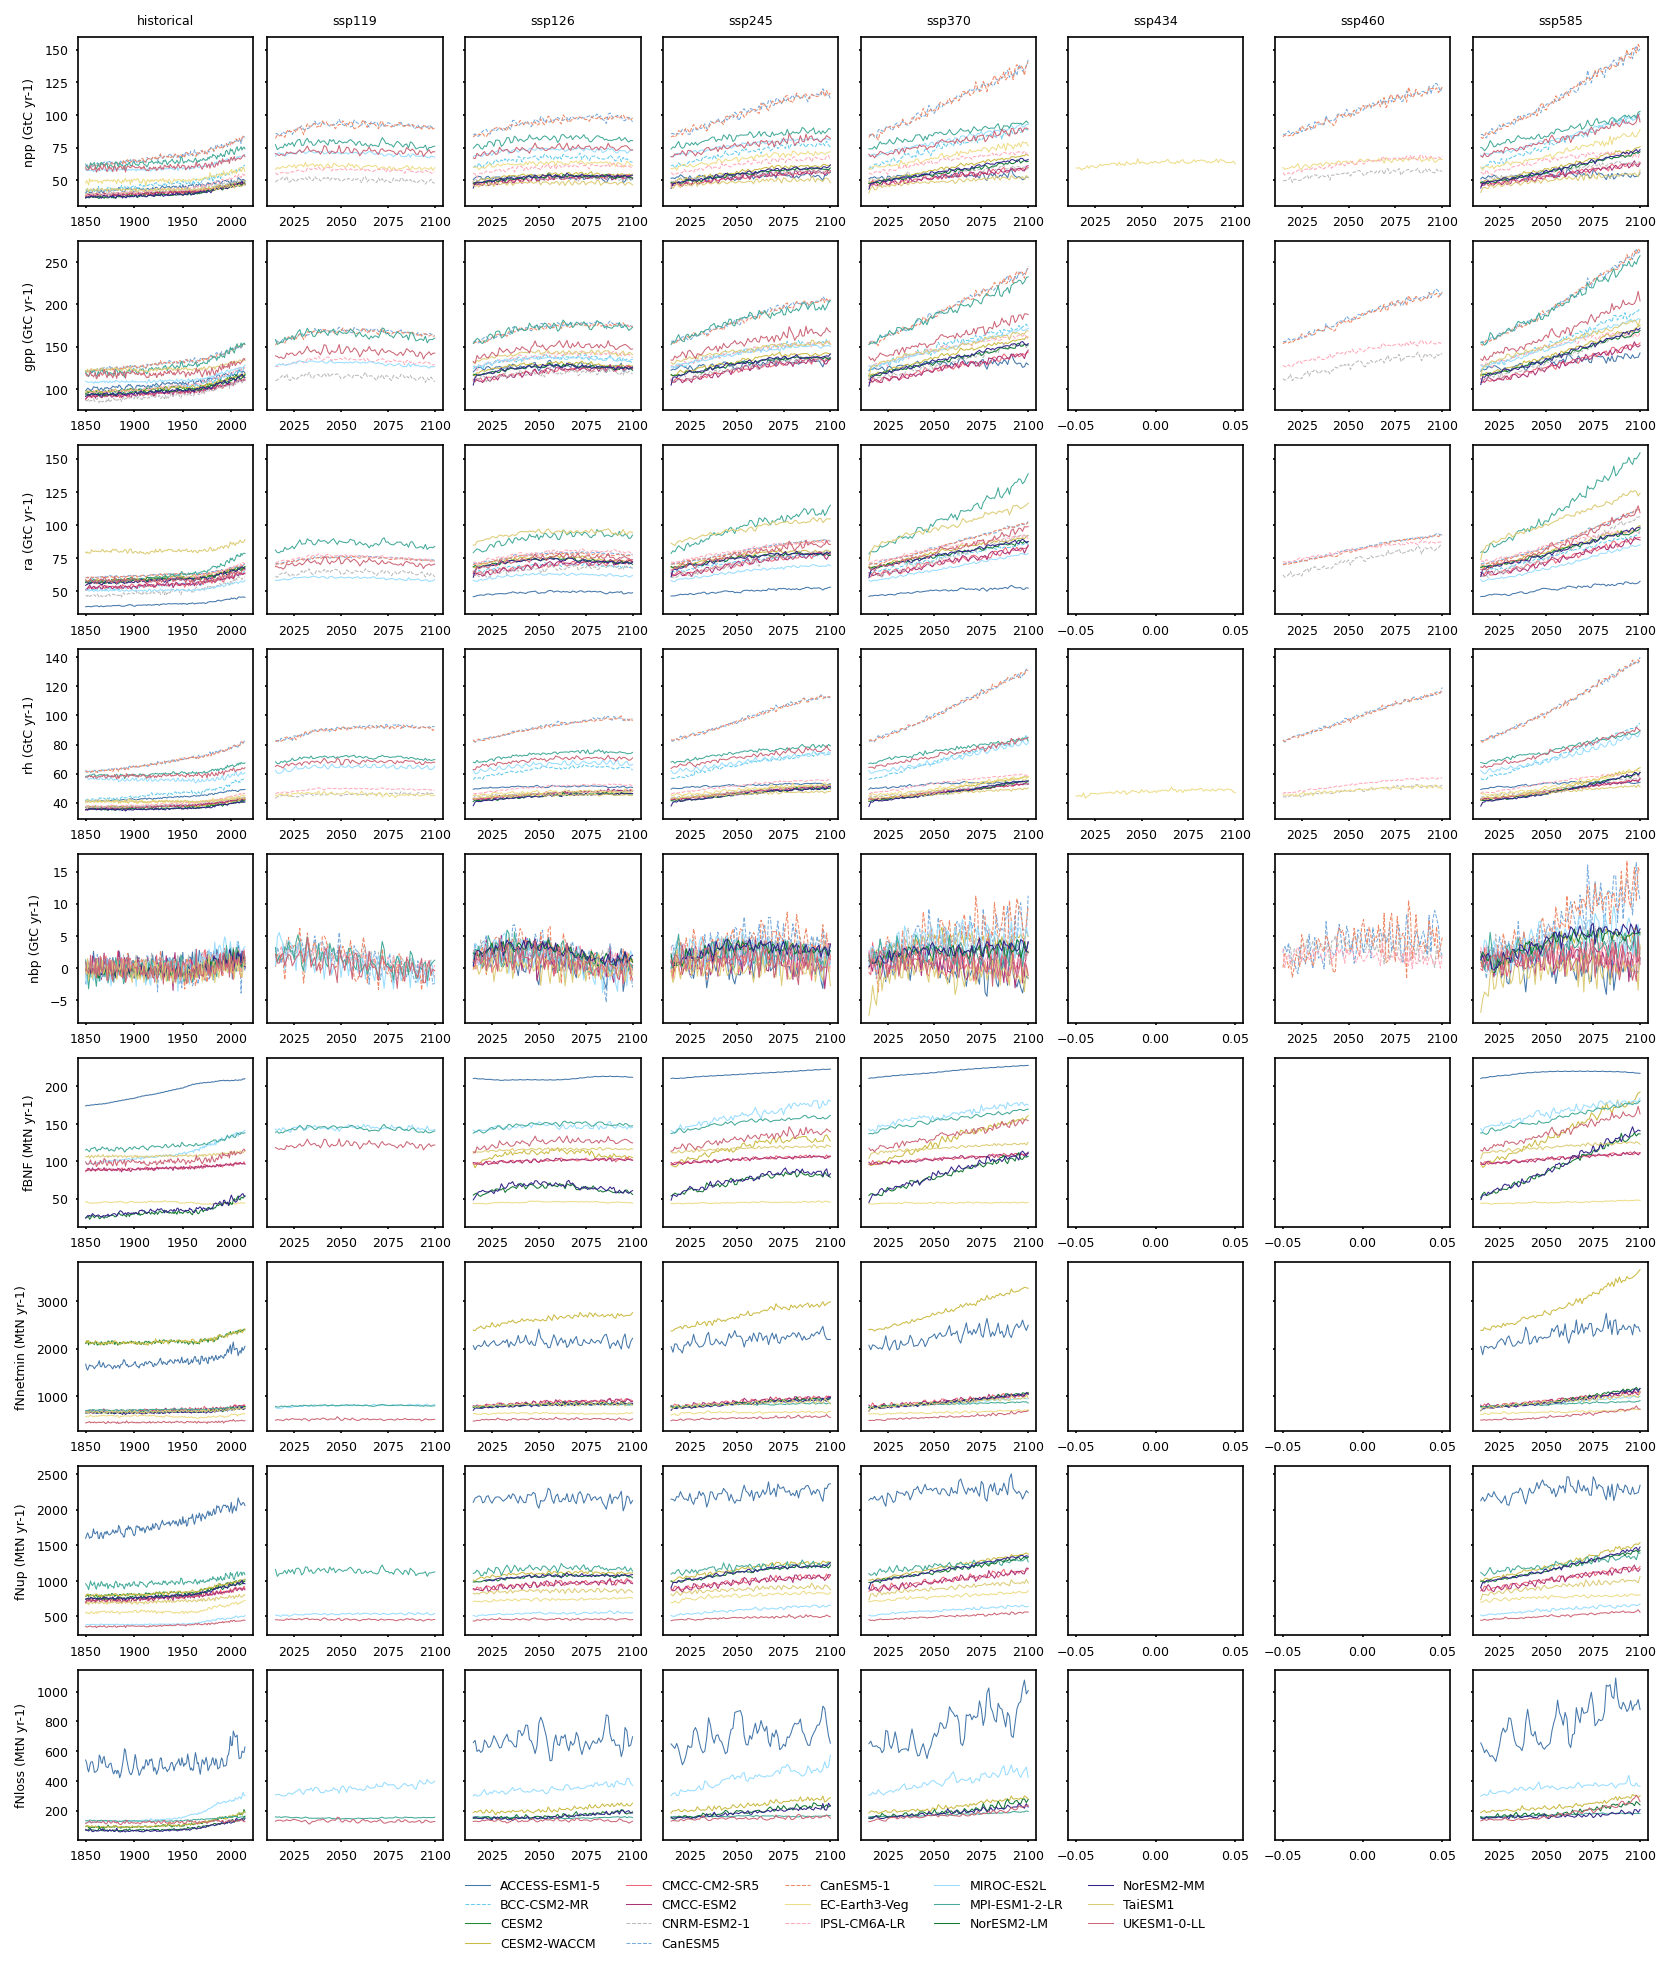

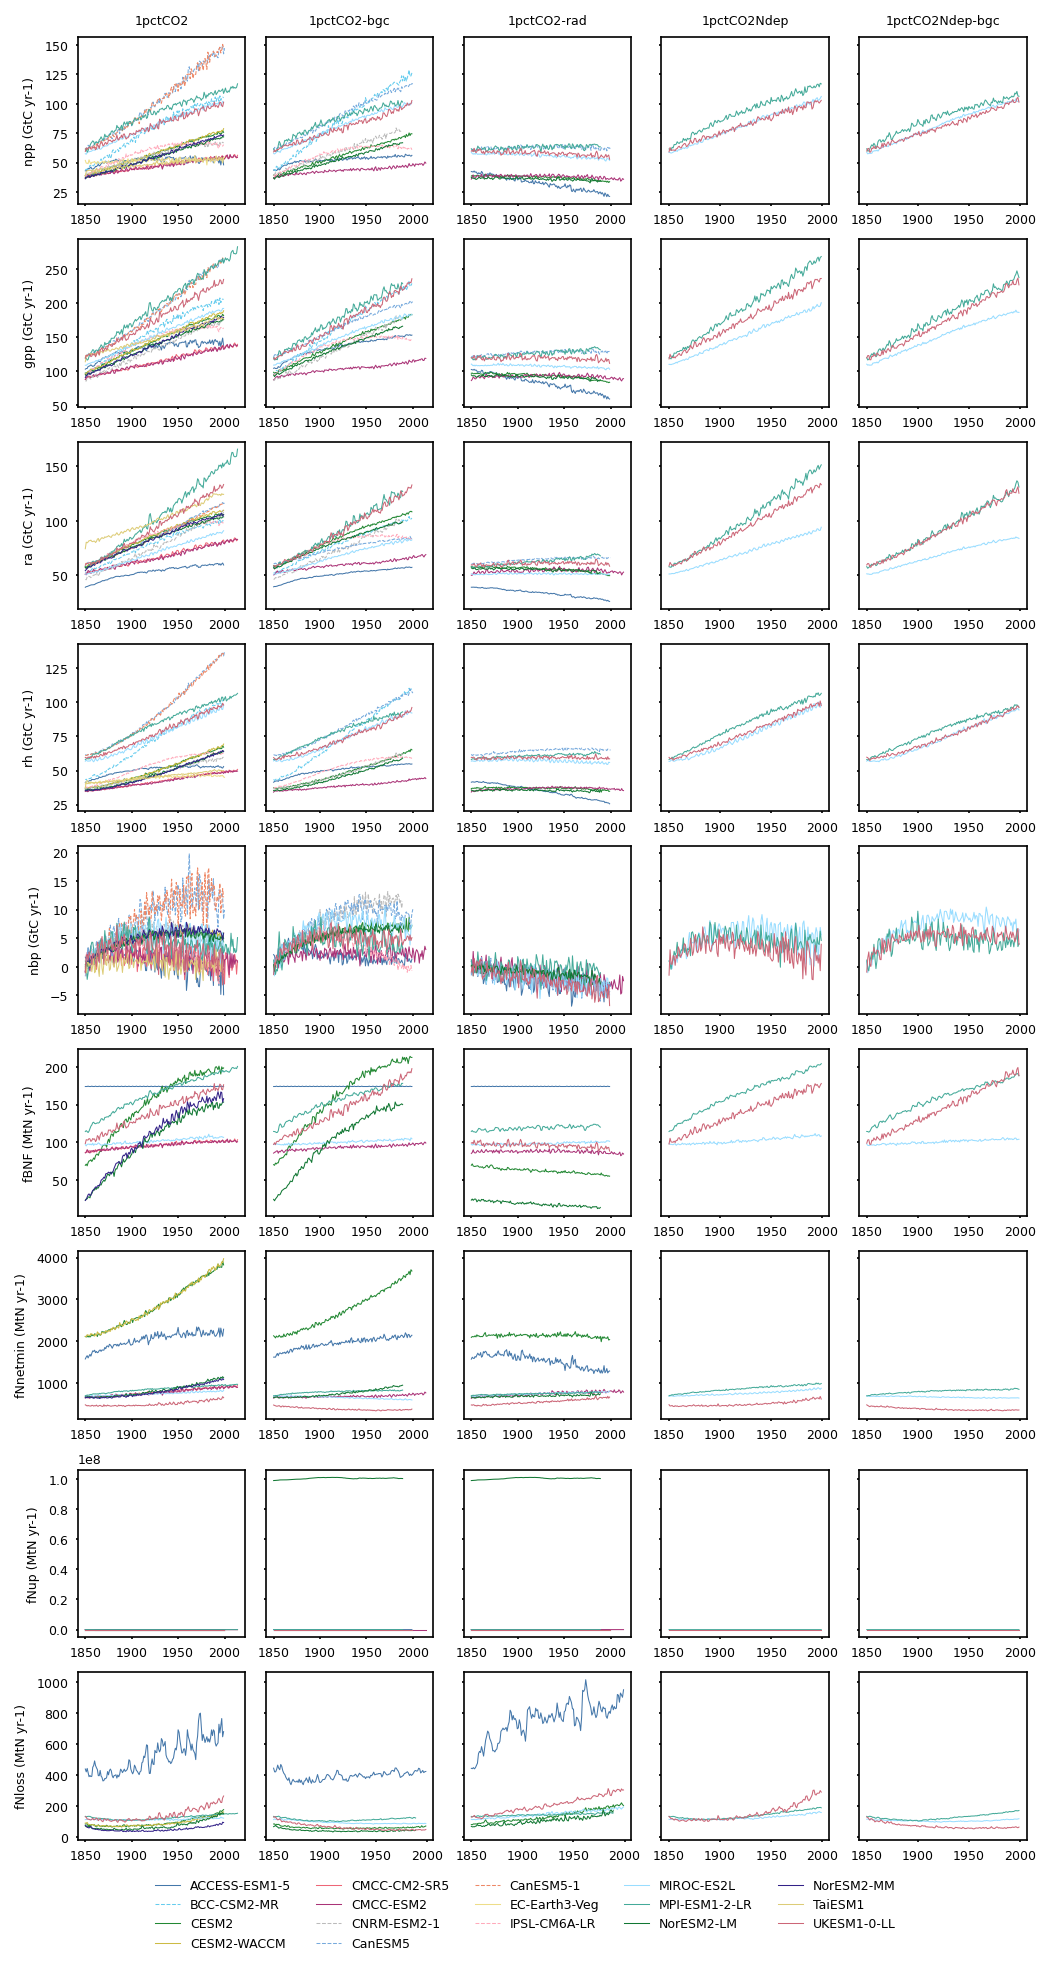

<IPython.core.display.Javascript object>

In [22]:
_plot_vars_by_exp(ds_global_annual_corrected, exp_list_histssp, flux_vars)
_plot_vars_by_exp(ds_global_annual_corrected, exp_list_1pctco2, flux_vars)

In [23]:
for var in flux_vars:
    for mdl in mdl_list:
        for exp in exp_list:
            da = ds_global_annual_corrected[var].sel(model=mdl, experiment=exp)
            mean = da.mean().data

            if mean > 1e6:
                print(f"\n{var} | {mdl} | {exp} | {mean}")
                ds_global_annual_corrected[var].loc[dict(model=mdl, experiment=exp)] = (
                    np.nan
                )


fNup | NorESM2-LM | 1pctCO2-bgc | 100294648.0

fNup | NorESM2-LM | 1pctCO2-rad | 100294648.0


<IPython.core.display.Javascript object>

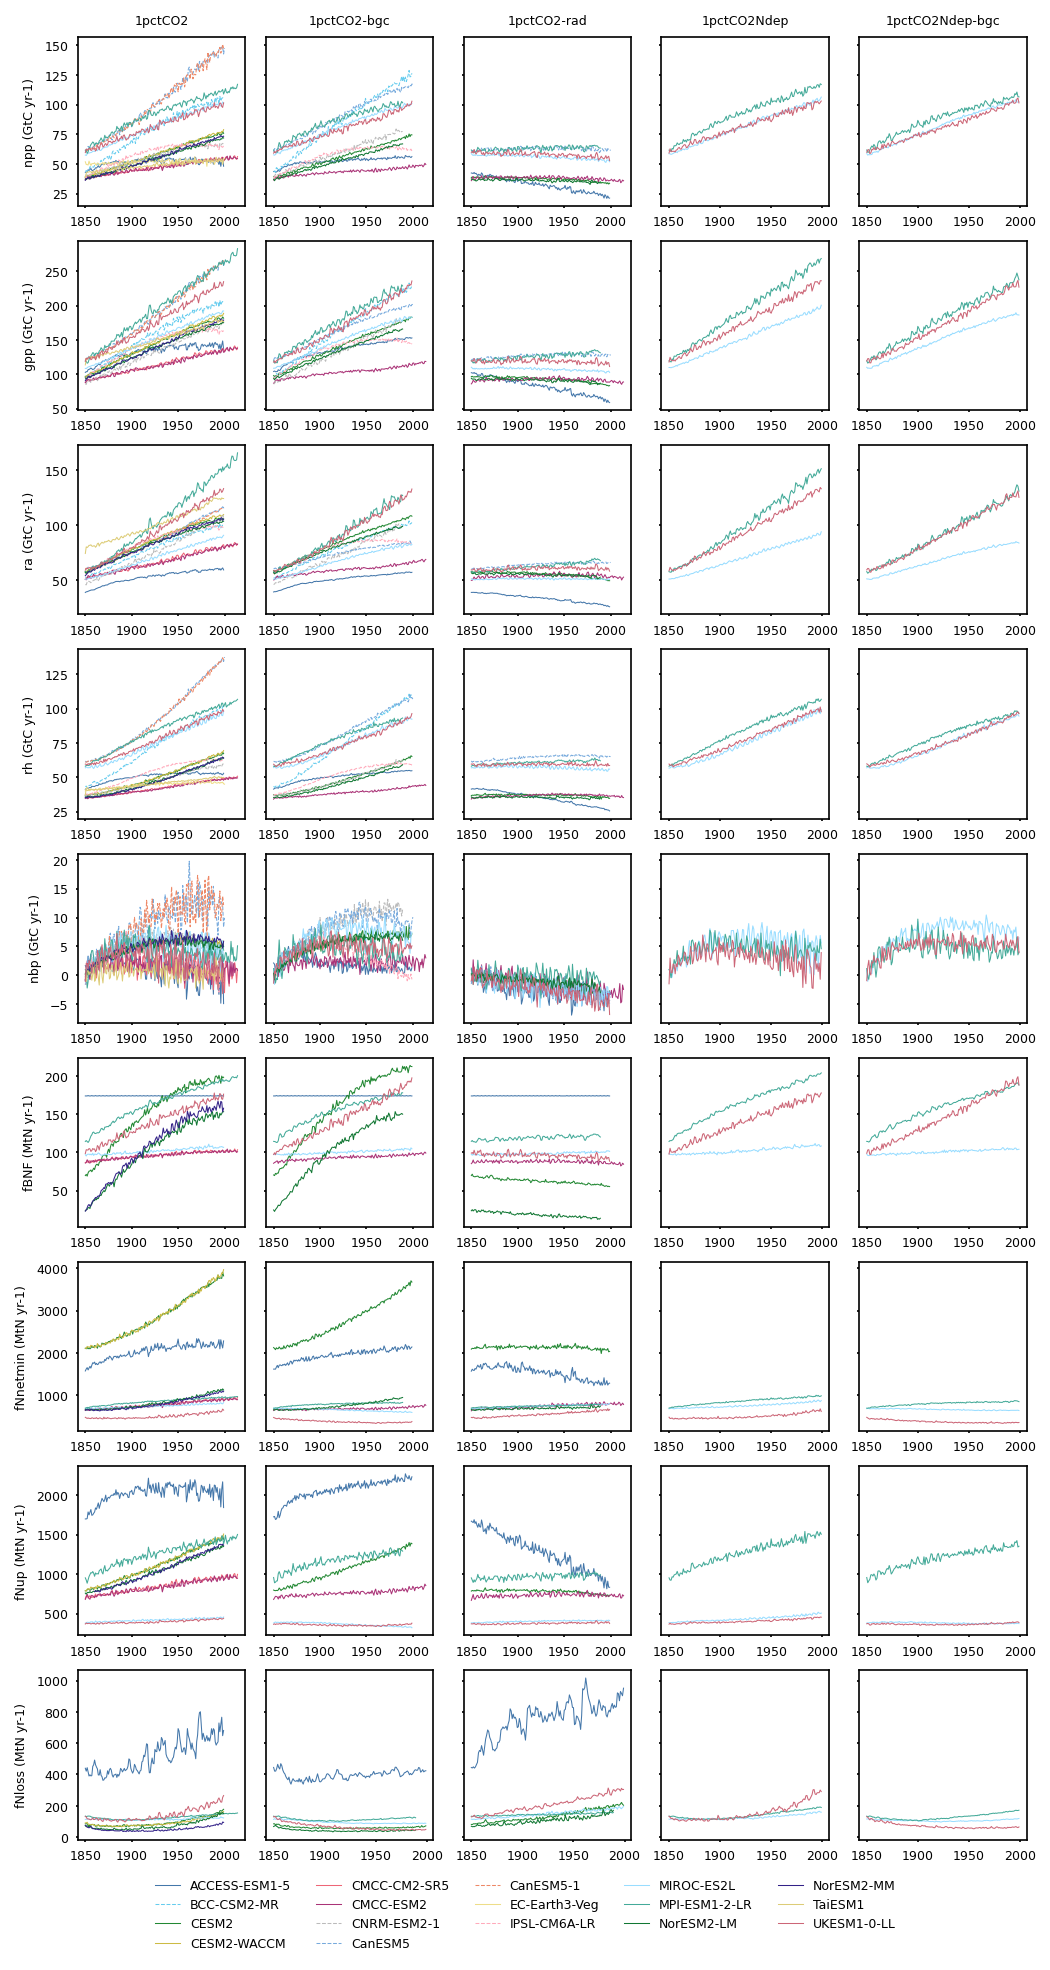

<IPython.core.display.Javascript object>

In [24]:
_plot_vars_by_exp(ds_global_annual_corrected, exp_list_1pctco2, flux_vars)

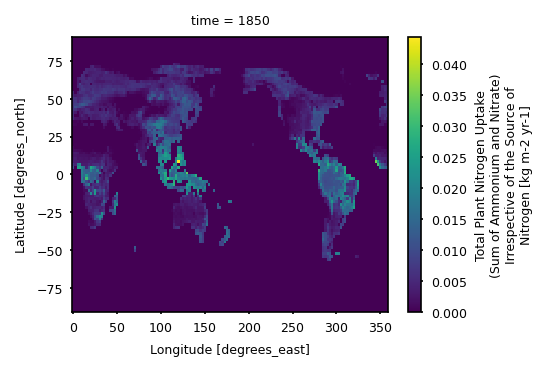

<IPython.core.display.Javascript object>

In [25]:
ds = xr.open_dataset(
    [f for f in file_paths if "NorESM2-LM" in f.name and "historical" in f.name][0]
)
ds["fNup"].sel(time=1850).plot()

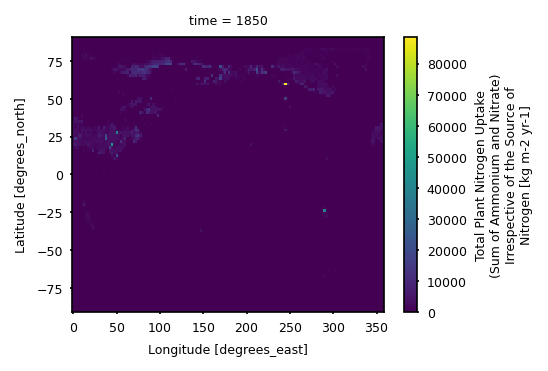

<IPython.core.display.Javascript object>

In [26]:
ds = xr.open_dataset(
    [f for f in file_paths if "NorESM2-LM" in f.name and "1pctCO2-bgc" in f.name][0]
)
fNup = ds["fNup"]
fNup.sel(time=1850).plot()

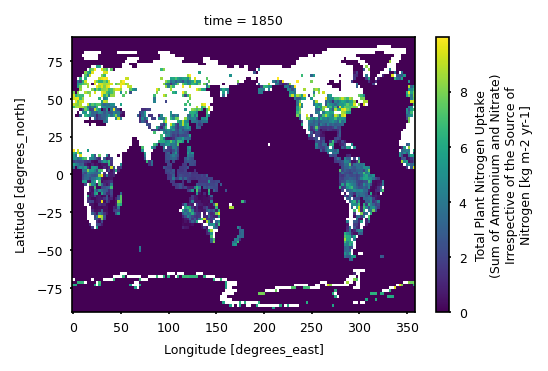

<IPython.core.display.Javascript object>

In [27]:
fNup_corr = fNup.where(fNup <= 10)
fNup_corr.sel(time=1850).plot()

In [28]:
ds_global_annual_corrected.attrs = {
    "summary": "Gloabl annual carbon-nitrogen cycle data derived from original CMIP6 monthly data",
    "creator_and_contact": "Gang Tang; gang.tang.au@gmail.com",
    "creation_date": datetime.now().strftime("%Y-%m-%dT%H:%M:%S"),
    "comment": (
        "Original CMIP6 monthly data were first processed to annual data. "
        "State variables were aggregated as annual means (e.g., annual mean cLand on grids), "
        "while flux variables were aggregated as annual totals (e.g., annual total npp on grids). "
        "The month-to-annual aggregation was weighted by the number of days in each month, "
        "using the original calendar provided in the monthly data. "
        "For idealized experiments, some models reported years 001-150 or 101-250, "
        "while most models used 1850-2000. "
        "We shifted model years beginning with 001 or 101 to 1850 to make them consistent. "
        "The annual data were then combined with land area, calculated from the model-specific "
        "grid-cell area (areacella) and land fraction (sftlf), to obtain global annual land data. "
        "The units were converted to GtC or GtC yr-1 for carbon states and fluxes, respectively, "
        "and to GtN or MtN yr-1 for nitrogen states and fluxes, respectively."
    ),
    "correction_note": (
        "For the resulting global annual data, we checked the key state variables and identified "
        "anomalous values in the first year of some experiments, which resulted in jumps between "
        "1850 and 1851 or 2015 and 2016 that were considered unreasonable for state variables. "
        "We corrected the identified initial-year jumps (diff > 20 GtC or > 0.2 GtN; "
        "thresholds based on the magnitude and variability of the data) by linear extrapolation "
        "from the following two years. "
        "We also checked the key flux variables and found that fNup in NorESM2-LM for "
        "1pctCO2-bgc and 1pctCO2-rad was substantially different in magnitude from the other models "
        "(~1e8 MtN yr-1 vs. <2000 MtN yr-1). "
        "Further examination of the annual data at the grid level indicated that this was not "
        "a simple numerical issue and could not be resolved by removing the large values. "
        "Therefore, fNup for these two model-experiment combinations was set to NaN. "
        "The grid-level annual data for these two cases should therefore be treated with caution, "
        "as the underlying cause of the anomalous fNup values could not be identified or resolved."
    ),
}

<IPython.core.display.Javascript object>

In [30]:
output_path = (
    res_dir
    / "global_annual_data"
    / "CMIP6_ESM_carbon_nitrogen_cycle_outputs_global_annual_processed_by_Gang_Tang.nc"
)

if output_path.exists():
    print(f"Already exists, skip: {output_path.name}")

else:
    encoding = {
        var: {"zlib": True, "complevel": 4, "shuffle": True}
        for var in ds_global_annual_corrected.data_vars
    }
    ds_global_annual_corrected.to_netcdf(output_path, encoding=encoding)

<IPython.core.display.Javascript object>